# 07. Протокол погодного покрытия актуальной аналитической базы

## 1. Область исследования

Включаются все непустые группы аэропорт–месяц текущей аналитической базы по
времени C40 UTC, без отбора по исходу или погодным характеристикам. Дизайн
зафиксирован до новой загрузки METAR. Сохраняются все строки и обе метки.
Покрытие относится к текущей аналитической выборке; оно не подтверждает
репрезентативность исходного авиационного движения. Обучение не входит в этап.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
protocol=json.loads((R/'11_full_protocol.json').read_text(encoding='utf8'))
counts=pd.read_csv(R/'07_c40_month_counts.csv')
assert protocol['input_sha256']==manifest['input_sha256']
assert counts.rows.sum()==protocol['rows'] and counts.go_arounds.sum()==protocol['go_arounds']
assert len(counts)==protocol['groups']==968
assert counts.airport.nunique()==protocol['airports']==19
display(pd.DataFrame([{'Записи':protocol['rows'],'GoA':protocol['go_arounds'],
    'Аэропорты':protocol['airports'],'Группы аэропорт–месяц':protocol['groups'],
    'Запросы станция–год':len(protocol['jobs'])}]))
registry=counts.groupby('airport').agg(first_month=('month','min'),last_month=('month','max'),
    months=('month','size'),rows=('rows','sum'),go_arounds=('go_arounds','sum')).reset_index()
readable_table(registry)


,Записи,GoA,Аэропорты,Группы аэропорт–месяц,Запросы станция–год
0,6331485,18349,19,968,93


airport,first_month,last_month,months,rows,go_arounds
EDDB,2019-01,2023-05,53,148336,427
EDDF,2019-01,2023-01,49,604960,1884
EDDM,2019-01,2023-05,53,443203,1293
EGCC,2019-01,2021-02,26,87435,306
EGLL,2019-01,2023-05,53,631718,2400
EGSS,2019-01,2023-05,53,221348,631
EHAM,2019-01,2023-01,49,561481,1038
EIDW,2019-01,2023-05,53,263879,922
EKCH,2019-01,2023-01,49,243272,562
EPWA,2019-01,2023-05,53,177752,567


## 2. Временные границы и объем аналитических данных

Периоды определяются только присутствием записей в актуальном входе. Общий
интервал — январь 2019 — май 2023 года; границы аэропортов различаются.
EGCC заканчивается февралем 2021 года в данной аналитической базе. Поздние
записи исходного архива без C40 не добавляются в погодную выборку.
Пустые месяцы не требуют запросов ради искусственного выравнивания периодов.


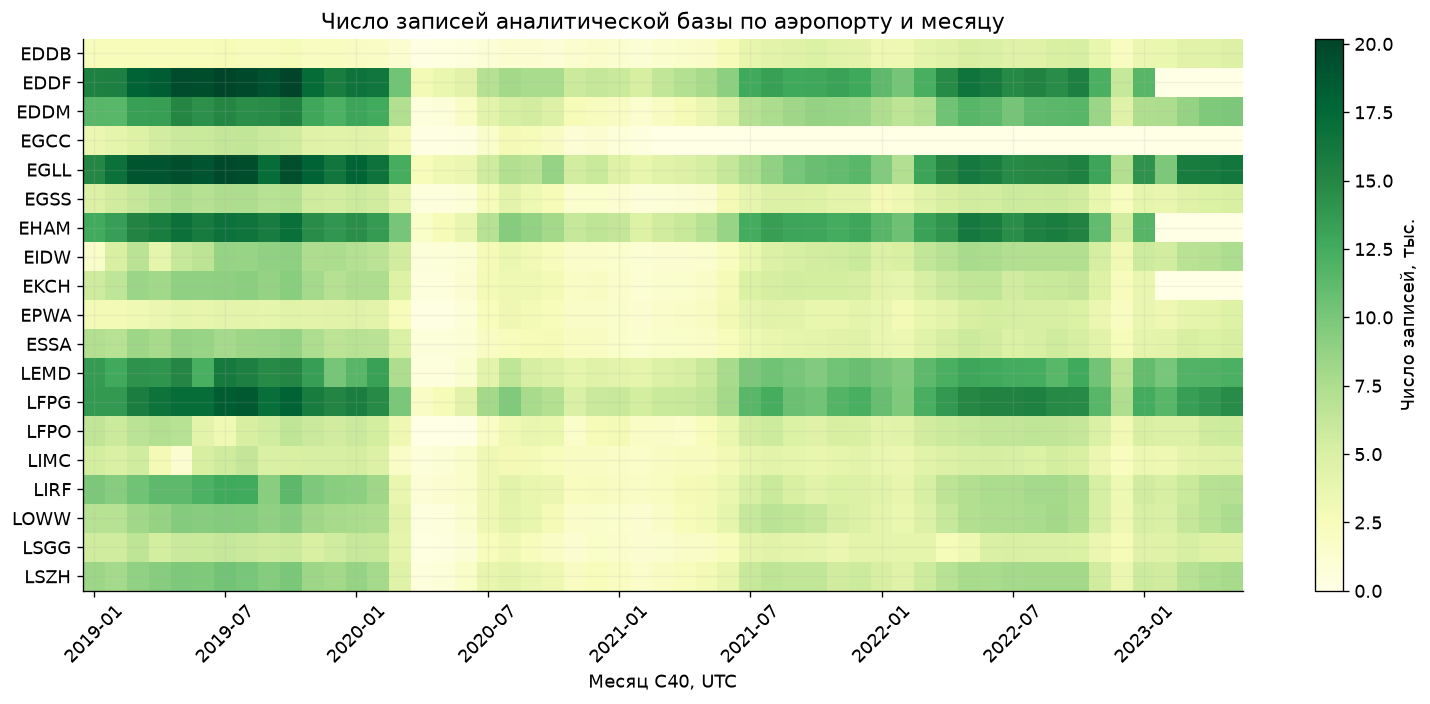

In [3]:
table=counts.pivot(index='airport',columns='month',values='rows').sort_index()
fig,ax=plt.subplots(figsize=(13,6))
im=ax.imshow(table.fillna(0).values/1000,cmap='YlGn',aspect='auto',vmin=0)
ticks=list(range(0,len(table.columns),6))
ax.set(yticks=range(len(table)),yticklabels=table.index,xticks=ticks,xticklabels=table.columns[ticks],
    xlabel='Месяц C40, UTC',title='Число записей аналитической базы по аэропорту и месяцу')
ax.tick_params(axis='x',rotation=45)
fig.colorbar(im,ax=ax,label='Число записей, тыс.')
save('21_full_input_monthly_registry')


## 3. Метаданные и идентичность станции

Для каждого аэропорта проверено наличие единственного ICAO-идентификатора
в сети IEM. Сохранены исходные GeoJSON, URL, SHA256 и время загрузки. Названия
и координаты отражают текущий каталог; историческое положение станции и
непрерывность METAR не считаются подтвержденными. Это особенно существенно
для изменений инфраструктуры аэропорта в течение исследуемого периода.
Код станции и временная отметка внутри каждого сырого сообщения проверяются
при загрузке. Выбор другой станции при отсутствии сообщения не применяется.


airport,network,name,latitude,longitude,archive_begin,source_url
EDDB,DE__ASOS,Berlin,52.3822,13.5325,1940-04-08,https://mesonet.agron.iastate.edu/geojson/network/DE__ASOS.geojson
EDDF,DE__ASOS,Frankfurt,50.0258,8.5214,1928-01-01,https://mesonet.agron.iastate.edu/geojson/network/DE__ASOS.geojson
EDDM,DE__ASOS,Munich,48.3583,11.8092,1929-08-01,https://mesonet.agron.iastate.edu/geojson/network/DE__ASOS.geojson
EGCC,GB__ASOS,Manchester,53.3537,-2.2750,1933-09-30,https://mesonet.agron.iastate.edu/geojson/network/GB__ASOS.geojson
EGLL,GB__ASOS,London,51.4785,-0.4614,1948-11-30,https://mesonet.agron.iastate.edu/geojson/network/GB__ASOS.geojson
EGSS,GB__ASOS,London,51.8812,0.2232,1972-12-31,https://mesonet.agron.iastate.edu/geojson/network/GB__ASOS.geojson
EHAM,NL__ASOS,Amsterdam,52.3154,4.7902,1932-05-03,https://mesonet.agron.iastate.edu/geojson/network/NL__ASOS.geojson
EIDW,IE__ASOS,Dublin,53.4215,-6.2977,1972-12-31,https://mesonet.agron.iastate.edu/geojson/network/IE__ASOS.geojson
EKCH,DK__ASOS,Copenhagen,55.6142,12.6453,1929-08-01,https://mesonet.agron.iastate.edu/geojson/network/DK__ASOS.geojson
EPWA,PL__ASOS,Warsaw,52.1628,20.9611,1928-01-02,https://mesonet.agron.iastate.edu/geojson/network/PL__ASOS.geojson


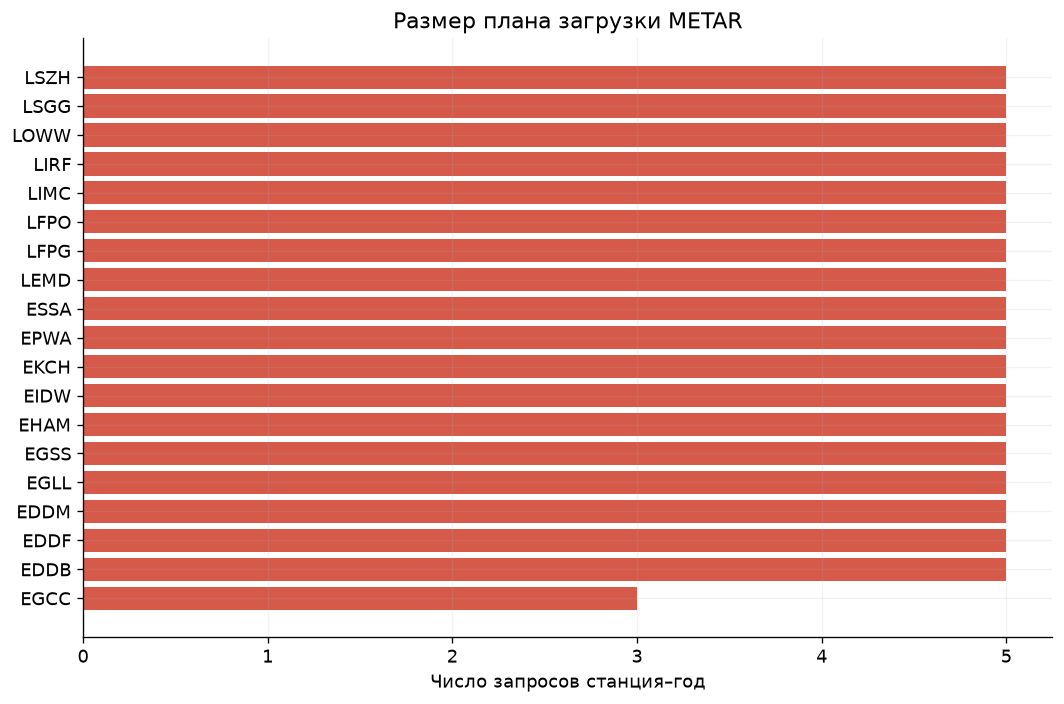

,airport,year,start_utc,end_utc,rows,go_arounds
0,EDDB,2019,2019-01-01T00:00:00+00:00,2020-01-01T00:00:00+00:00,28762,65
1,EDDB,2020,2020-01-01T00:00:00+00:00,2021-01-01T00:00:00+00:00,13117,35
2,EDDB,2021,2021-01-01T00:00:00+00:00,2022-01-01T00:00:00+00:00,35640,99
3,EDDB,2022,2022-01-01T00:00:00+00:00,2023-01-01T00:00:00+00:00,50306,153
4,EDDB,2023,2023-01-01T00:00:00+00:00,2023-06-01T00:00:00+00:00,20511,75
...,...,...,...,...,...,...
88,LSZH,2019,2019-01-01T00:00:00+00:00,2020-01-01T00:00:00+00:00,110036,366
89,LSZH,2020,2020-01-01T00:00:00+00:00,2021-01-01T00:00:00+00:00,43458,190
90,LSZH,2021,2021-01-01T00:00:00+00:00,2022-01-01T00:00:00+00:00,51260,175
91,LSZH,2022,2022-01-01T00:00:00+00:00,2023-01-01T00:00:00+00:00,78758,282


In [4]:
stations=[]
for source in protocol['station_metadata']:
    path=DATA/'station_metadata'/f"{source['network']}.geojson"
    assert sha(path)==source['sha256']
    matches=[f for f in json.loads(path.read_text(encoding='utf8'))['features'] if f['id']==source['airport']]
    assert len(matches)==1
    p=matches[0]['properties']
    stations.append({'airport':source['airport'],'network':source['network'],'name':p['sname'],
        'latitude':source['coordinates'][1],'longitude':source['coordinates'][0],
        'archive_begin':p.get('archive_begin'),'source_url':source['url']})
readable_table(pd.DataFrame(stations))
jobs=pd.DataFrame(protocol['jobs'])
requests_by_airport=jobs.groupby('airport').size().sort_values()
fig,ax=plt.subplots(figsize=(9,6))
ax.barh(requests_by_airport.index,requests_by_airport.values,color=CORAL)
ax.set(xlabel='Число запросов станция–год',title='Размер плана загрузки METAR',xticks=range(6))
save('22_full_request_plan')
display(jobs[['airport','year','start_utc','end_utc','rows','go_arounds']])


## 4. Загрузка, сохранение прогресса и сопоставление

Запрос охватывает присутствующий период станции внутри года, включая
предшествующие сутки. Routine и special сохраняются в исходных байтах.
Годовой блок — техническая единица загрузки; отчеты строятся по месяцам C40.
Контрольные SHA256 связывают вход, сырой ответ и результат. Завершенный блок
не обрабатывается повторно при возобновлении без проверки версии кода и файлов.

Для предполагаемых задержек 0/5/10/15 минут выбирается последнее наблюдение
строго до C40 с учетом задержки. Затем проверяются давность 30/60/90 минут,
неоднозначность, полный разбор или основные поля и наличие COR. Замечание к
качеству не вызывает переход к более старой погоде. Основной предел — 60 минут.
Ни отсутствие погоды, ни плохой разбор не удаляют аналитическую запись.


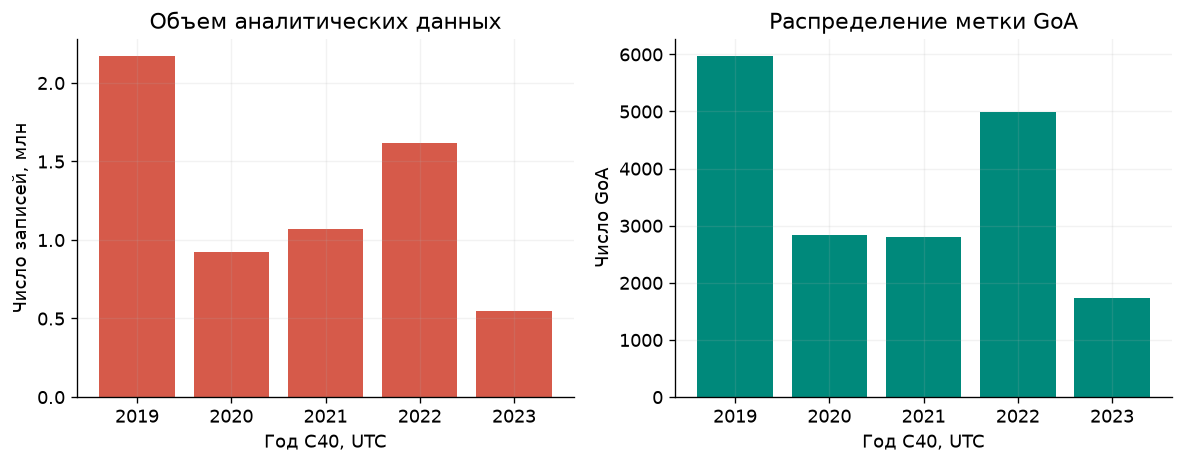

,rows,go_arounds
year,,
2019,2172291,5973
2020,923609,2845
2021,1069160,2808
2022,1619848,4984
2023,546577,1739


In [5]:
annual=counts.assign(year=counts.month.str[:4]).groupby('year')[['rows','go_arounds']].sum()
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].bar(annual.index,annual.rows/1000000,color=CORAL)
axes[0].set(ylabel='Число записей, млн',xlabel='Год C40, UTC',title='Объем аналитических данных')
axes[1].bar(annual.index,annual.go_arounds,color=GREEN)
axes[1].set(ylabel='Число GoA',xlabel='Год C40, UTC',title='Распределение метки GoA')
save('23_full_input_annual_counts')
display(annual)


## 5. Правила аудита и ограничения интерпретации

Все неизвестные коды, пропуски, различные тексты на одной отметке и COR
сохраняются в диагностике. Проверка основных полей не исправляет полный текст.
Интервал между архивными строками не доказывает отсутствие передачи со станции.
При отличии годовой выгрузки от прежнего месячного снимка изменение учитывается
отдельно. Перекрытие предшествующих суток не должно удваивать аналитические строки.

Время наблюдения не является доказательством времени получения METAR.
Доступность целевого аэропорта к C40, обработка пропусков и временное разделение
данных должны быть определены до обучения. Исторические координаты станции и
изменения инфраструктуры требуют отдельной проверки при интерпретации результатов.


In [6]:
import unittest,test_decode_metar,test_full_weather_pipeline
suite=unittest.TestSuite([unittest.defaultTestLoader.loadTestsFromModule(m) for m in [test_decode_metar,test_full_weather_pipeline]])
result=unittest.TextTestRunner(stream=sys.stdout,verbosity=1).run(suite)
assert result.wasSuccessful()
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==protocol['input_sha256']


.

.

.

.

.

...

.

.

.

.

----------------------------------------------------------------------
Ran 20 tests in 0.011s

OK
